# Heat diffusion
*An energy check on the host*

> The time steps are one captured graph. Every few steps the field is copied to host memory and a host
> function checks that heat is never created. You write the loop once, and it runs with or without a GPU.

**Time:** ~6 min · **Runs on:** CPU (a GPU is picked up automatically and runs a larger plate) · **You need:** eagle, hawk, NumPy and matplotlib; read first: {doc}`../graph_across_devices`

The step is the explicit heat step of [hawk's heat diffusion page](https://amasat01.github.io/hawk/content/vocabulary/09_heat_diffusion.html):
a plate with its edge held at zero, `u + r (up + down + left + right - 4 u)`, with `r` = 0.2. The kernel is explained
there; here it is the same code, and the lesson is what eagle does around it. Dimensionless units: cells and steps.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import gpu_available, plot_style, to_numpy, xp_for

In [3]:
import numpy as np

DEVICE = "gpu" if gpu_available() else "cpu"
xp = xp_for(DEVICE)
N = 256 if DEVICE == "gpu" else 48
R = 0.2
print("running on", DEVICE, f"with a {N} x {N} plate")

running on cpu with a 48 x 48 plate


## The plate's words

Say the vocabulary first. The plate is a field of temperatures `u` and one number `r`, the share of the gap to the neighbours' average that a cell closes in one step. Declare them once as a `KernelKind`; the kernel below is written in these names.

In [4]:
from hawk import Param, Scalar
from hawk.ext import DATA_ONLY, KernelKind


class Plate(KernelKind, slug="plate"):
    u: Scalar               # temperature of a cell
    r: Param                # diffusion number: kappa dt / h^2, at most 1/4 for a stable step
    guard = DATA_ONLY

Plate

__main__.Plate

## The kernel

The same kernel as in hawk, written as a function of the plate width. A `Grid` names the lane axes, and
`u.at(row=..., col=...)` reads a neighbour.

In [5]:
import eagle
import hawk
import hawk.math as m
from hawk import Grid, Param, Scalar


def heat_kernel(width):
    @Plate
    def heat_step(lane: Grid["row", "col":width], u, r) -> Scalar:
        i, j = lane.row, lane.col
        if m.land(m.land(i > 0, i < width - 1), m.land(j > 0, j < width - 1)):
            out = u + r * (u.at(row=i - 1, col=j) + u.at(row=i + 1, col=j)
                           + u.at(row=i, col=j - 1) + u.at(row=i, col=j + 1) - 4.0 * u)
        else:
            out = 0.0                    # the edge is held at zero
        return out
    return heat_step


def blob(width):
    """Zero everywhere except a warm square in the middle."""
    u = np.zeros((width, width))
    c, k = width // 2, width // 8
    u[c - k:c + k, c - k:c + k] = 1.0
    return u


heat_step = heat_kernel(N)

## The check, as a host function

After every block of steps the graph copies the field into a host array. A host function reads it and keeps three
numbers: the total heat, the peak and the minimum. It flags a rise in the total (it raises an error), because the edge
can only take heat away. The peak and the minimum must stay between the start values 0 and 1.

The host array is page-locked memory on a GPU (`eagle.pinned`), so the copy is a direct transfer that can overlap with
kernels. Pinning is your decision: eagle never does it for you. On the CPU an ordinary array does the same job.

In [6]:
class Watch:
    """Reads the copied field, keeps its total, peak and minimum, and raises if the total rises."""

    def __init__(self, field):
        self.field, self.total, self.peak, self.low = field, [], [], []

    def __call__(self):
        field = np.asarray(self.field)              # a NumPy view of the (pinned) host array: plain reads in a host function
        total = float(field.sum())
        if self.total and total > self.total[-1] * (1 + 1e-12):
            raise RuntimeError(f"heat grew: {self.total[-1]} -> {total}")
        self.total.append(total)
        self.peak.append(float(field.max()))
        self.low.append(float(field.min()))

## The graph

One replay is `STEPS` steps, then the copy, then the check. The two arrays take turns as input and output, so `STEPS`
is even and the field is back in `a` at the end of a replay. `heat_step(u=..., buffer=...)` is a GPU node when its planes
are device arrays and a host node when they are NumPy arrays; `eagle.copy` moves the field home; `eagle.opaque(fn, reads=..., writes=...)`
makes your own Python function a graph node; `reads=` and `writes=` tell eagle which arrays it touches, so it can order it
(here, after the copy).

In [7]:
STEPS = 8
CHECKS = 40 if DEVICE == "cpu" else 1140   # a bigger plate takes longer for the heat to reach the edge


def make_block(watch, r=R):
    @eagle.Graph.builder
    def block(a, b, h_field):
        g = eagle.Graph()
        for _ in range(STEPS // 2):
            heat_step(u=a, r=r, buffer=b)        # a -> b
            heat_step(u=b, r=r, buffer=a)        # b -> a
        eagle.copy(a, into=h_field)              # device -> host (a plain copy on the CPU)
        eagle.opaque(watch, reads=(h_field,), writes=(), name="watch")
        return g
    return block


u0 = blob(N)
a, b = xp.array(u0), xp.zeros((N, N))
h_field = eagle.pinned((N, N))
watch = Watch(h_field)
g = make_block(watch)(a, b, h_field)
print("backend:", g.backend, "| nodes:", g.node_labels()[-3:], "...")
print("schedule:", g.schedule)

backend: cpu | nodes: ['heat_step#8', 'copy', 'watch'] ...
schedule: ('work_share', 'work_share', 'work_share', 'work_share', 'work_share', 'work_share', 'work_share', 'work_share', 'work_share', 'work_share')


## Run it

`g.launch(CHECKS)` replays the graph `CHECKS` times and waits. On a GPU it is one captured graph, host function
included, and the host does not step in between. Afterwards the host arrays are safe to read. A bigger plate takes more
steps for the heat to reach the edge, so the GPU plate gets more replays; the check should see the total fall.

In [8]:
g.launch(CHECKS)
print(f"{CHECKS} replays of {STEPS} steps = {CHECKS * STEPS} steps; {len(watch.total)} checks on the host")
print(f"total heat {watch.total[0]:.4f} -> {watch.total[-1]:.4f}; peak {watch.peak[0]:.4f} -> {watch.peak[-1]:.4f}")
assert watch.total[-1] < 0.99 * watch.total[0], "heat reached the edge, so the check had something to see"
assert len(watch.total) == CHECKS
assert max(watch.peak) <= 1.0 + 1e-12 and min(watch.low) >= -1e-12, "the field stays between its start values"

40 replays of 8 steps = 320 steps; 40 checks on the host
total heat 144.0000 -> 118.1888; peak 0.9984 -> 0.1627


## Check it against NumPy

Matching the same steps written with array slices tests the graph. The physics checks, against the exact decay of the lowest sine mode, are on hawk's page.

In [9]:
def numpy_steps(u, k):
    for _ in range(k):
        out = np.zeros_like(u)
        out[1:-1, 1:-1] = u[1:-1, 1:-1] + R * (u[:-2, 1:-1] + u[2:, 1:-1] + u[1:-1, :-2] + u[1:-1, 2:] - 4.0 * u[1:-1, 1:-1])
        u = out
    return u


TOL = 1e-12
err = np.abs(to_numpy(a) - numpy_steps(u0, CHECKS * STEPS)).max()
assert err < TOL, err
print(f"{CHECKS * STEPS} steps: largest difference from NumPy {err:.1e} < {TOL:g}")

320 steps: largest difference from NumPy 5.6e-17 < 1e-12


The total heat and the peak, as the host saw them after each block of steps. The total stays flat while the warm square is
away from the edge and falls once heat reaches it:


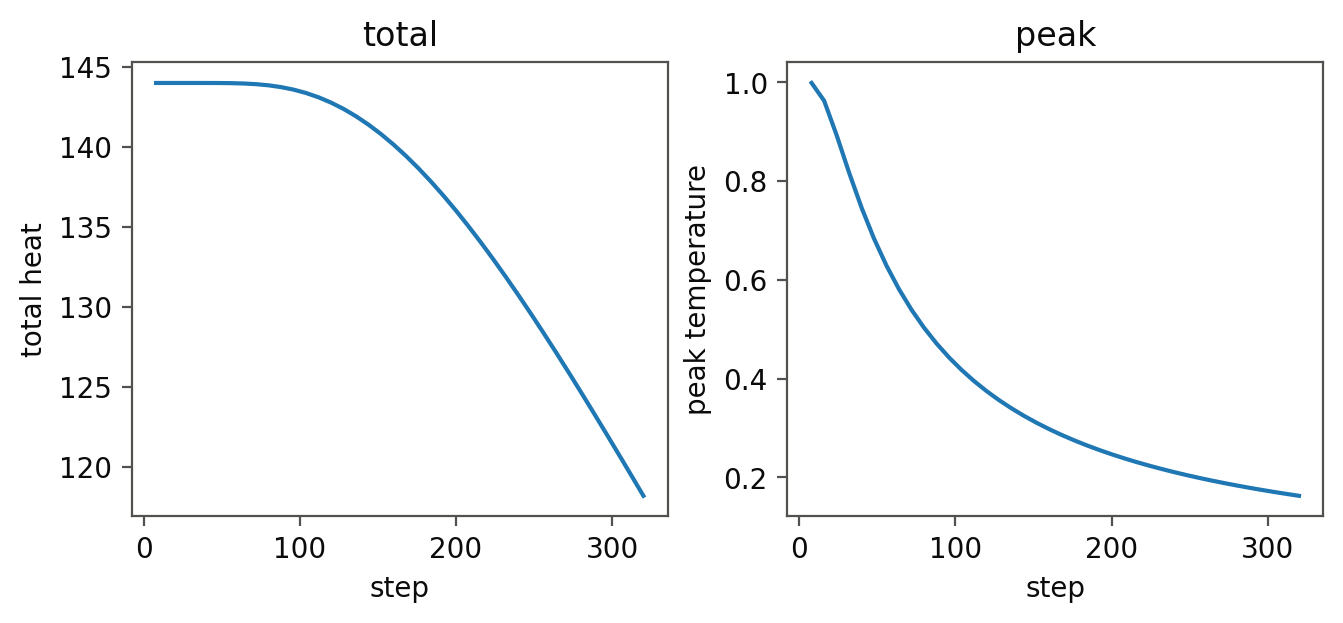
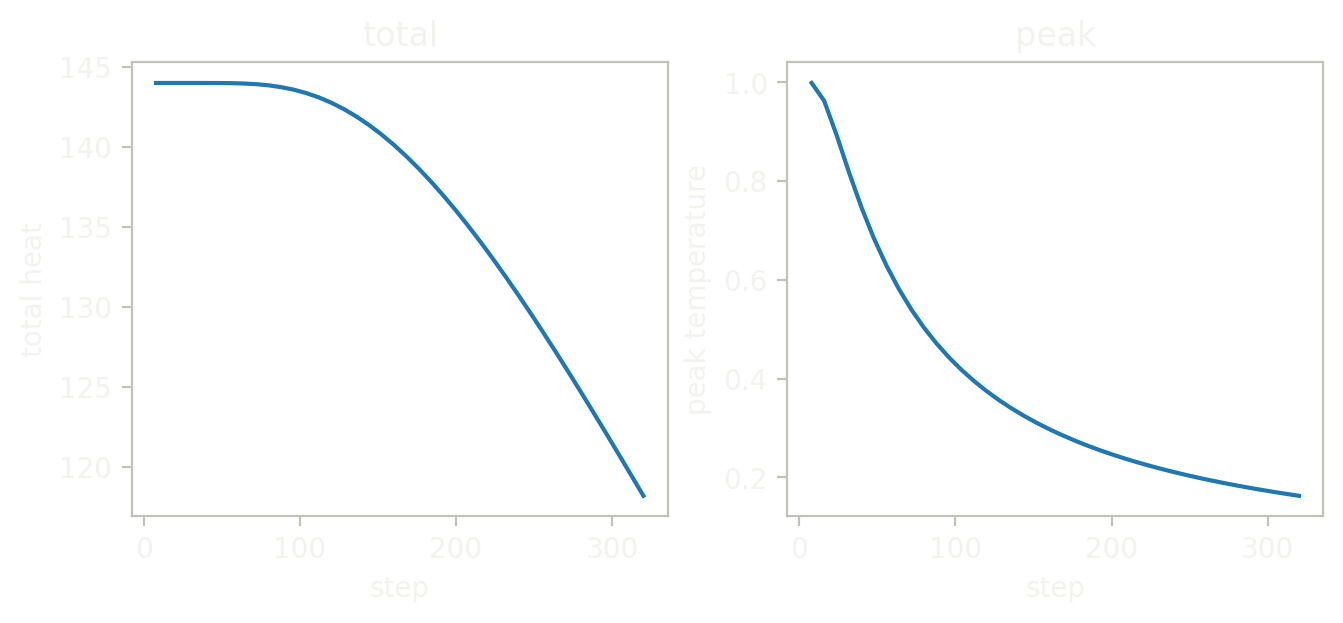

In [10]:
import matplotlib.pyplot as plt
from themed_figure import show

plot_style()
steps_axis = STEPS * (1 + np.arange(CHECKS))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.6, 3.0), constrained_layout=True)
ax1.plot(steps_axis, watch.total)
ax1.set_xlabel("step"); ax1.set_ylabel("total heat"); ax1.set_title("total")
ax2.plot(steps_axis, watch.peak)
ax2.set_xlabel("step"); ax2.set_ylabel("peak temperature"); ax2.set_title("peak")
show()

## When the check fires

The check is only worth having if it can fail. An explicit step is stable for `r <= 0.25`; with `r` = 0.3 the plate
is unstable and the total soon rises. The same builder, built with that `r`, makes the host function raise. A host
function cannot raise through the CUDA thread, so eagle keeps the error and raises it when `launch` returns. On a GPU
the replays already queued still run first; on the CPU the run stops at once.

In [11]:
bad_u, bad_b, bad_h = xp.array(u0), xp.zeros((N, N)), eagle.pinned((N, N))
bad = make_block(Watch(bad_h), r=0.3)(bad_u, bad_b, bad_h)
try:
    bad.launch(CHECKS)
except RuntimeError as err:
    print("the check fired:", err)
else:
    raise AssertionError("the check should have flagged the unstable run")

the check fired: heat grew: 143.93486032714554 -> 143.9931248518982


## What just happened

- The steps, the copy and the host check were one graph. On a GPU it was captured once and replayed `CHECKS` times.
- The host function ran after each copy, in replay order. When it raised (the unstable run), eagle re-raised the error
  from `launch`.
- Copying the whole field keeps the example plain: the copy is the lesson. A device reduction and a copy of a few numbers
  would move less data.
- Without a GPU the same builder ran over NumPy arrays; nothing in the code changed.
- A host node adds a small cost to every replay and buys one replayable object that does not block the host. See
  {doc}`../graph_across_devices` for the cost line and the refusals.

## Try this

Set `STEPS = 2` and multiply `CHECKS` by 4: the same steps, checked four times as often.

## Next

- {doc}`23_fluids_pinned_frames`: frames copied home while the steps carry on.
- {doc}`../graph_across_devices`: the rules for host nodes and copies.